# Corridor Environmental Compliance — Final Analysis (BDA25707)
**Simanta Karmaker · Supervisor: Farzana Sharmin Mou · Ravensbourne University London**

Anonymised 172 km linear-infrastructure corridor, South Asia · Oct 2020 – Nov 2023 · four domains (air, surface water, groundwater, noise).
Structured on **CRISP-DM**: Business/Data Understanding → Data Preparation → Modeling → Evaluation → Deployment.

**Aim:** predict, before a sample is taken, whether a reading will exceed its regulatory standard, so that monitoring can be prioritised.

### Methodological safeguards
1. **No target leakage.** An earlier version built `value_roll3` with `.rolling(3)` on `value`, which *includes the current
   month*. The target is `value > rule_limit`, so the model was handed (an average containing) the answer.
   Every feature is now built from **lagged** values only, so it exists *before* the sample is taken.
2. **Leakage audit (§5)** quantifies what that bug was worth — a reportable methodological result.
3. **Baselines (§6):** parameter-only and no-value-features models expose the honest ceiling.
4. **SMOTE sensitivity (§8)** on weak domains, applied *inside training folds only*.
5. **Four-config ablation (§9):** tests whether typology carries signal at all (D vs A) and whether it adds
   anything beyond raw position (C vs B).
6. **Deterministic de-duplication:** a stable sort with an explicit tiebreak, so every run reproduces identical values.

### Data and outputs
The raw monitoring records are not public. Only anonymised aggregates leave the notebook (§15); these are the files in
the repository's `dashboard/data/` folder. Outputs shown are from the original run. Before publication, printouts that
listed raw rows or location identifiers were removed or reduced to counts, and the private project folder was renamed.

**Run top to bottom (Runtime → Run all)** with the input files in `IN_DIR` (§0).


## §0 Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Raw inputs are not included in the repository. IN_DIR must hold:
#   env_monitoring_long.csv, summary_extracted.csv, site_typology.csv, chainage_to_siteid.csv
IN_DIR  = '/content/drive/MyDrive/corridor_project'
OUT_DIR = f'{IN_DIR}/analysis'
DASH    = f'{OUT_DIR}/dashboard'
TYPOLOGY_CSV = f'{IN_DIR}/site_typology.csv'
CH_MAP_CSV   = f'{IN_DIR}/chainage_to_siteid.csv'

import os
for p in (OUT_DIR, DASH, f'{OUT_DIR}/shap'): os.makedirs(p, exist_ok=True)
print('Input :', IN_DIR); print('Files :', os.listdir(IN_DIR))


In [3]:
!pip install -q xgboost shap imbalanced-learn

## §1 Data Understanding — load

In [4]:
import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')

a = pd.read_csv(f'{IN_DIR}/env_monitoring_long.csv'); a['source']='monthly'
b = pd.read_csv(f'{IN_DIR}/summary_extracted.csv');   b['source']='summary'
df = pd.concat([a,b], ignore_index=True)
print(f"monthly {len(a):,} + summary {len(b):,} = combined raw {len(df):,} rows")

monthly 4,850 + summary 4,237 = combined raw 9,087 rows


## §2 Data Preparation — domain fix, cleaning, de-duplication

In [5]:
PARAM_DOMAIN = {
    'CO':'air','NO':'air','NO2':'air','SO2':'air','O3':'air','VOC':'air',
    'PM10':'air','PM2.5':'air','AirTemp':'air',
    'Noise_Day':'noise','Noise_Night':'noise',
    'BOD5':'surface_water','COD':'surface_water','TSS':'surface_water',
    'DO':'surface_water','Oil_Grease':'surface_water','TOC':'surface_water',
    'TP':'surface_water','Temp':'surface_water',
    'TDS':'ground_water','As':'ground_water','Fe':'ground_water',
    'Mn':'ground_water','S':'ground_water','Cl':'ground_water',
}
# summary parser mislabels air as surface_water -> reassign by parameter; pH keeps its original domain
df['domain'] = df.apply(lambda r: r['domain'] if r['parameter']=='pH'
                        else PARAM_DOMAIN.get(r['parameter'], r['domain']), axis=1)

df = df.dropna(subset=['value','parameter','report_month'])
df = df[df['report_month']!='UNKNOWN']
df['report_date'] = pd.to_datetime(df['report_month']+'-15', errors='coerce')
df = df.dropna(subset=['report_date'])

df['src_priority'] = df['source'].map({'monthly':1,'summary':2})     # monthly wins on overlap
# v4: deterministic de-duplication. A stable sort (mergesort) plus an explicit
# tiebreak makes the kept duplicate independent of input row order, so every
# run of this notebook reproduces identical values.
_tiebreak = [c for c in ['file','value'] if c in df.columns]
df = (df.sort_values(['src_priority'] + _tiebreak, kind='mergesort')
        .drop_duplicates(subset=['report_month','domain','chainage','parameter'], keep='first')
        .drop(columns='src_priority'))
print(f"after cleaning & dedupe: {len(df):,} rows\n")
print(df['domain'].value_counts())

after cleaning & dedupe: 4,406 rows

domain
surface_water    2072
air              1605
ground_water      557
noise             172
Name: count, dtype: int64


### §2b Regulatory standards by date, and the exceedance target

In [6]:
ECR_1997 = {
    'CO':('le',10000),'NO':('le',100),'NO2':('le',100),'SO2':('le',365),'O3':('le',235),
    'PM10':('le',150),'PM2.5':('le',65),'Noise_Day':('le',60),'Noise_Night':('le',50),
    'BOD5':('le',6),'COD':('le',50),'TSS':('le',150),'DO':('ge',5),'Oil_Grease':('le',10),
    'pH_SW':('range',(6.0,9.0)),'TDS':('le',1000),'As':('le',0.05),'Fe':('le',1.0),
    'Mn':('le',0.1),'Cl':('le',600),'S':('le',0.05),'pH_GW':('range',(6.5,8.5)),
}
ECR_2023 = dict(ECR_1997); ECR_2023['NO2']=('le',80); ECR_2023['SO2']=('le',80); ECR_2023['O3']=('le',100)
CHANGE = pd.Timestamp('2023-06-01')

def rule_for(p,dom,dt):
    t = ECR_2023 if dt>=CHANGE else ECR_1997
    key = 'pH_SW' if (p=='pH' and dom=='surface_water') else ('pH_GW' if p=='pH' else p)
    return t.get(key)

def flag(v,r):
    if r is None or pd.isna(v): return np.nan
    kind,lim = r
    if kind=='le': return int(v>lim)
    if kind=='ge': return int(v<lim)
    if kind=='range':
        lo,hi = lim; return int(v<lo or v>hi)
    return np.nan

rules = [rule_for(p,dm,dt) for p,dm,dt in zip(df.parameter, df.domain, df.report_date)]
df['rule_limit']   = [r[1] if r else None for r in rules]
df['exceedance']   = [flag(v,r) for v,r in zip(df.value, rules)]
df['has_standard'] = df['rule_limit'].notna().astype(int)
print(f"records with a standard: {df.has_standard.sum():,}")
print(f"exceedances: {int(df.exceedance.sum(skipna=True)):,} ({df.exceedance.mean()*100:.1f}%)")

records with a standard: 3,497
exceedances: 704 (20.1%)


### §2c EDA

,domain,parameter,n,exceedances,rate_pct
17,surface_water,BOD5,275,229.0,83.3
19,surface_water,DO,275,168.0,61.1
4,air,PM10,295,77.0,26.1
12,ground_water,S,81,21.0,25.9
15,noise,Noise_Day,86,22.0,25.6
5,air,PM2.5,295,63.0,21.4
11,ground_water,Mn,81,13.0,16.0
10,ground_water,Fe,81,13.0,16.0
18,surface_water,COD,275,38.0,13.8
21,surface_water,TSS,254,32.0,12.6


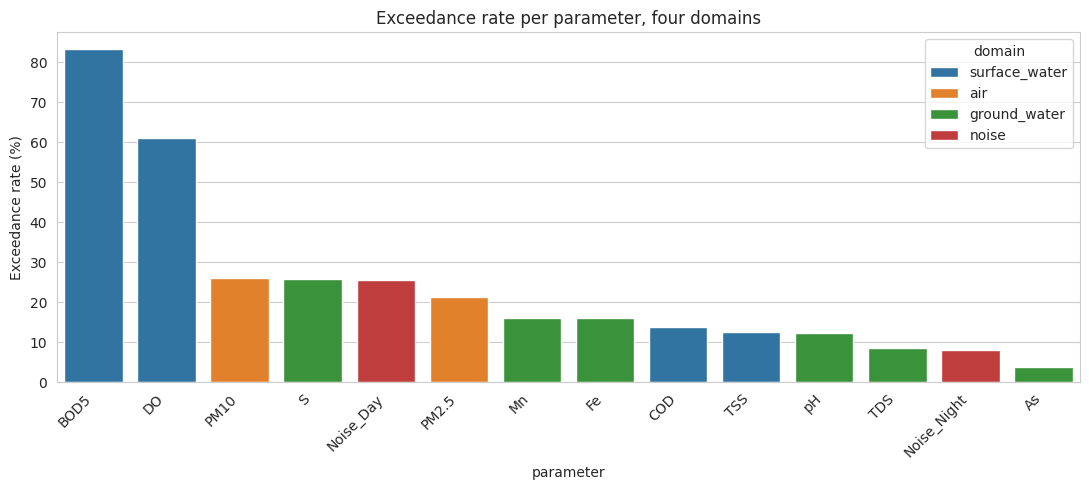

In [7]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')
s = df[df.has_standard==1]

summary = (s.groupby(['domain','parameter'])
             .agg(n=('exceedance','size'), exceedances=('exceedance','sum'))
             .assign(rate_pct=lambda x:(x.exceedances/x.n*100).round(1))
             .reset_index().sort_values('rate_pct', ascending=False))
display(summary)
summary.to_csv(f'{OUT_DIR}/eda_exceedance_by_parameter.csv', index=False)

plt.figure(figsize=(11,5))
sns.barplot(data=summary.head(15), x='parameter', y='rate_pct', hue='domain', dodge=False)
plt.xticks(rotation=45, ha='right'); plt.ylabel('Exceedance rate (%)')
plt.title('Exceedance rate per parameter, four domains')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_eda_parameters.png', dpi=150); plt.show()

### §2d Link every reading to its typology site
Reading chainages carry sampling-point suffixes (such as `(US-25m)`) and embedded newlines that the typology file
lacks, so a raw string merge fails. A numeric key (`km*1000 + m`) is parsed on both sides.

In [8]:
import re
typ = pd.read_csv(TYPOLOGY_CSV)
if 'chainage' not in typ.columns:
    typ = typ.merge(pd.read_csv(CH_MAP_CSV), on='site_id', how='left')
if 'site_id' not in typ.columns:
    typ = typ.merge(pd.read_csv(CH_MAP_CSV), on='chainage', how='left')

def chkey(c):
    m = re.match(r'\s*(\d+)\s*\+\s*(\d+)', str(c).replace('\n',' '))
    return int(m.group(1))*1000 + int(m.group(2)) if m else np.nan

typ['_chkey'] = typ['chainage'].map(chkey)
df['_chkey']  = df['chainage'].map(chkey)
df['site_id']   = df['_chkey'].map(dict(zip(typ['_chkey'], typ['site_id'])))
df['zone_type'] = df['_chkey'].map(dict(zip(typ['_chkey'], typ['zone_type'])))
print(f"readings mapped to a typology site: {df.site_id.notna().mean()*100:.1f}% "
      f"({df.site_id.notna().sum():,}/{len(df):,})")
print(f"distinct sites: {df.site_id.nunique()}  (raw chainage labels: {df.chainage.nunique()})")
print(f"\nreadings with no typology entry (reported as a limitation): {df.site_id.isna().sum():,}")

readings mapped to a typology site: 78.8% (3,473/4,406)
distinct sites: 38  (raw chainage labels: 136)

readings with no typology entry (reported as a limitation): 933


## §3 Feature engineering — **leakage fixed**

Every feature must be knowable **before** the sample is taken, otherwise the model cannot support the
decision it is built for (deciding where to sample next month).

| feature | available before sampling? |
|---|---|
| `parameter_code`, `rule_limit_num`, `chainage_km`, calendar features | yes — known in advance |
| `value_lag1` — last month's reading at this site+parameter | yes |
| `value_roll3` — mean of the **previous three** readings | yes (**fixed**) |
| ~~`value_roll3_LEAKY`~~ — rolling mean **including this month** | **no** — contains the target |

`value_roll3_LEAKY` is retained **only** to quantify the bug in §5; it is never used in any reported model.

In [9]:
d = df.copy()
d['rule_limit_num'] = pd.to_numeric(
    d['rule_limit'].apply(lambda x: x[1] if isinstance(x,(tuple,list)) else x), errors='coerce')
d['parameter_code'] = d['parameter'].astype('category').cat.codes
d['chainage_km']    = d['_chkey']/1000.0
d['month_num']      = d['report_date'].dt.month
d['year']           = d['report_date'].dt.year
d['is_monsoon']     = d['month_num'].isin([5,6,7,8,9,10]).astype(int)
d['is_dry']         = 1 - d['is_monsoon']

d = d.sort_values(['parameter','chainage','report_date'])
GRP = ['parameter','chainage']
d['value_lag1'] = d.groupby(GRP)['value'].shift(1)                       # strictly past
# FIXED: rolling mean of the LAGGED series -> mean(value[t-1], value[t-2], value[t-3])
d['value_roll3'] = (d.groupby(GRP)['value_lag1'].rolling(3, min_periods=1)
                      .mean().reset_index(level=[0,1], drop=True))
# LEAKY (audit only): rolling on raw value -> includes value[t], which defines the target
d['value_roll3_LEAKY'] = (d.groupby(GRP)['value'].rolling(3, min_periods=1)
                            .mean().reset_index(level=[0,1], drop=True))

TEMPORAL = ['month_num','year','is_monsoon','is_dry']
BASE     = ['parameter_code'] + TEMPORAL + ['rule_limit_num']
FEATURES = BASE + ['chainage_km','value_lag1','value_roll3']
FEATURES_LEAKY = BASE + ['chainage_km','value_lag1','value_roll3_LEAKY']
CUTOFF  = pd.Timestamp('2022-07-01')
DOMAINS = {'surface_water':'primary','air':'primary','ground_water':'preliminary','noise':'preliminary'}

print("correlation with the current value (the thing that defines the target):")
print(f"  value_roll3        (fixed) : {d['value'].corr(d['value_roll3']):.3f}")
print(f"  value_roll3_LEAKY  (old)   : {d['value'].corr(d['value_roll3_LEAKY']):.3f}   <-- contains value[t]")
print("\nFEATURES:", FEATURES)

correlation with the current value (the thing that defines the target):
  value_roll3        (fixed) : 0.823
  value_roll3_LEAKY  (old)   : 0.942   <-- contains value[t]

FEATURES: ['parameter_code', 'month_num', 'year', 'is_monsoon', 'is_dry', 'rule_limit_num', 'chainage_km', 'value_lag1', 'value_roll3']


## §4 Modelling toolkit — nested time-series CV, threshold tuning, optional SMOTE

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from imblearn.over_sampling import SMOTE

def make(name, y):
    if name=='Logistic Regression': return LogisticRegression(max_iter=1000, class_weight='balanced')
    if name=='Random Forest': return RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                            random_state=42, n_jobs=-1)
    spw = max((y==0).sum(),1)/max((y==1).sum(),1)
    return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08, eval_metric='logloss',
                         random_state=42, scale_pos_weight=spw)

def tune_thr(y, p):
    g = np.linspace(0.1,0.9,17)
    return float(g[int(np.argmax([f1_score(y,(p>=t).astype(int), zero_division=0) for t in g]))])

def _resample(X, y, use_smote):
    if not use_smote: return X, y
    nmin = int(np.sum(y))
    if nmin < 2 or len(np.unique(y)) < 2: return X, y
    try:  return SMOTE(k_neighbors=min(5, max(1, nmin-1)), random_state=42).fit_resample(X, y)
    except Exception: return X, y

def prep_folds(train, test=None):
    # lag/rolling gaps filled from TRAIN medians only (no leakage across the split)
    out = []
    for frame in [train, test]:
        if frame is None: out.append(None); continue
        f = frame.copy()
        for col in ['value_lag1','value_roll3','value_roll3_LEAKY']:
            if col in f.columns:
                med = train.groupby('parameter')[col].median(); gm = train[col].median()
                f[col] = f[col].fillna(f['parameter'].map(med)).fillna(gm)
        out.append(f)
    return out

def nested_cv(X, y, name, outer=5, inner=3, use_smote=False):
    X = X.reset_index(drop=True); y = y.reset_index(drop=True)
    sc = (name=='Logistic Regression'); rows = []
    for tr, te in TimeSeriesSplit(n_splits=outer).split(X):
        thr = []
        for a, b in TimeSeriesSplit(n_splits=inner).split(X.iloc[tr]):
            yy = y.iloc[tr].iloc[a]
            if yy.nunique() < 2: continue
            A, B = X.iloc[tr].iloc[a], X.iloc[tr].iloc[b]
            if sc:
                s = StandardScaler().fit(A); A = s.transform(A); B = s.transform(B)
            A2, y2 = _resample(np.asarray(A), np.asarray(yy), use_smote)
            m = make(name, pd.Series(y2)); m.fit(A2, y2)
            thr.append(tune_thr(y.iloc[tr].iloc[b], m.predict_proba(B)[:,1]))
        t = float(np.mean(thr)) if thr else 0.5
        yo = y.iloc[tr]
        if yo.nunique() < 2: continue
        A, B = X.iloc[tr], X.iloc[te]
        if sc:
            s = StandardScaler().fit(A); A = s.transform(A); B = s.transform(B)
        A2, y2 = _resample(np.asarray(A), np.asarray(yo), use_smote)
        m = make(name, pd.Series(y2)); m.fit(A2, y2)
        p = m.predict_proba(B)[:,1]; yh = (p>=t).astype(int); Y = y.iloc[te]
        rows.append(dict(precision=precision_score(Y,yh,zero_division=0),
                         recall=recall_score(Y,yh,zero_division=0),
                         f1=f1_score(Y,yh,zero_division=0),
                         roc_auc=roc_auc_score(Y,p) if Y.nunique()>1 else np.nan, thr=t))
    return pd.DataFrame(rows)

def domain_frame(dom, feats):
    sub = d[d.domain==dom].dropna(subset=['exceedance']).copy()
    tr0 = sub[sub.report_date < CUTOFF]
    train, test = prep_folds(tr0, sub[sub.report_date >= CUTOFF])
    train = train.dropna(subset=feats+['exceedance']); test = test.dropna(subset=feats+['exceedance'])
    return sub, train, test

print("toolkit ready")

toolkit ready


## §5 Leakage audit — what the bug was worth
Same model, same folds, one feature swapped. The gap is the inflation the old pipeline reported.
**This is a reportable methodological result**, not just a bug fix.

In [11]:
audit = []
for dom in DOMAINS:
    for tag, feats in [('leaky (old code)', FEATURES_LEAKY), ('fixed (this notebook)', FEATURES)]:
        _, train, _ = domain_frame(dom, feats)
        y = train.exceedance.astype(int)
        if len(train) < 60 or y.nunique() < 2: continue
        outer = 5 if len(train) >= 300 else 3
        r = nested_cv(train[feats], y, 'XGBoost', outer, 3).mean()
        audit.append(dict(domain=dom, features=tag, cv_f1=round(r.f1,3),
                          cv_recall=round(r.recall,3), cv_auc=round(r.roc_auc,3)))
audit_df = pd.DataFrame(audit)
piv = audit_df.pivot(index='domain', columns='features', values='cv_f1')
piv['inflation_F1'] = (piv['leaky (old code)'] - piv['fixed (this notebook)']).round(3)
display(audit_df); display(piv)
audit_df.to_csv(f'{OUT_DIR}/leakage_audit.csv', index=False)
print("\nPositive inflation = the old pipeline over-reported by that much.")

,domain,features,cv_f1,cv_recall,cv_auc
0,surface_water,leaky (old code),0.456,0.778,0.760
1,surface_water,fixed (this notebook),0.433,0.654,0.740
2,air,leaky (old code),0.568,0.616,0.829
3,air,fixed (this notebook),0.458,0.599,0.825
4,ground_water,leaky (old code),0.323,0.339,0.670
5,ground_water,fixed (this notebook),0.249,0.295,0.715
6,noise,leaky (old code),0.588,0.556,0.885
7,noise,fixed (this notebook),0.549,0.699,0.806


features,fixed (this notebook),leaky (old code),inflation_F1
domain,,,
air,0.458,0.568,0.110
ground_water,0.249,0.323,0.074
noise,0.549,0.588,0.039
surface_water,0.433,0.456,0.023



Positive inflation = the old pipeline over-reported by that much.


## §6 Baselines — the honest ceiling
`parameter_code` alone can score well simply because BOD5 exceeds 84% of the time and pH 0.7%.
If the full model barely beats it, most apparent skill is parameter identity, not environmental prediction.
It is reported up front so the full model's gain can be judged against it.

In [12]:
rows = []
for dom in DOMAINS:
    for tag, feats in [('parameter_code only', ['parameter_code']),
                       ('no value features',   BASE + ['chainage_km']),
                       ('full (fixed)',        FEATURES)]:
        _, train, _ = domain_frame(dom, feats)
        y = train.exceedance.astype(int)
        if len(train) < 60 or y.nunique() < 2: continue
        outer = 5 if len(train) >= 300 else 3
        r = nested_cv(train[feats], y, 'XGBoost', outer, 3).mean()
        rows.append(dict(domain=dom, baseline=tag, cv_f1=round(r.f1,3), cv_recall=round(r.recall,3)))
baselines = pd.DataFrame(rows)
display(baselines.pivot(index='domain', columns='baseline', values='cv_f1'))
baselines.to_csv(f'{OUT_DIR}/baselines.csv', index=False)

baseline,full (fixed),no value features,parameter_code only
domain,,,
air,0.458,0.534,0.334
ground_water,0.249,0.232,0.224
noise,0.549,0.512,0.255
surface_water,0.433,0.369,0.355


## §7 Modelling — three classifiers per domain, nested time-series CV
Inner loop tunes the decision threshold; outer loop scores (mean ± std); the post-cutoff holdout is touched once.
Domains without post-cutoff readings are evaluated **CV-only** and reported as *preliminary* rather than dropped.

In [13]:
winners = {}; cv_report = []
for dom, tier in DOMAINS.items():
    sub, train, test = domain_frame(dom, FEATURES)
    ytr = train.exceedance.astype(int); yte = test.exceedance.astype(int)
    if len(train) < 40 or ytr.nunique() < 2:
        print(f"\n[skip {dom}: insufficient training data]"); continue
    holdout_ok = len(test) >= 10 and yte.nunique() > 1
    mode = 'CV + holdout' if holdout_ok else f'CV only ({len(test)} post-cutoff rows)'
    outer = 5 if len(train) >= 300 else 3
    print(f"\n===== {dom.upper()} ({tier}) | train {len(train)} test {len(test)} | {mode} | outer {outer} =====")
    best = None
    for name in ['Logistic Regression','Random Forest','XGBoost']:
        cv = nested_cv(train[FEATURES], ytr, name, outer, 3)
        if cv.empty: continue
        mn, sd = cv.mean(), cv.std()
        print(f"  {name:20s} CV F1 {mn.f1:.3f}±{sd.f1:.3f} | recall {mn.recall:.3f}±{sd.recall:.3f} "
              f"| precision {mn.precision:.3f} | AUC {mn.roc_auc:.3f} | thr {mn.thr:.2f}")
        cv_report.append(dict(domain=dom, tier=tier, model=name, evaluation=mode, imbalance='class_weight',
            cv_f1=round(mn.f1,3), cv_f1_std=round(sd.f1,3), cv_recall=round(mn.recall,3),
            cv_recall_std=round(sd.recall,3), cv_precision=round(mn.precision,3),
            cv_auc=round(mn.roc_auc,3), thr=round(mn.thr,2), holdout_f1=np.nan, holdout_recall=np.nan))
        if best is None or (mn.f1, mn.recall) > best[0]: best = ((mn.f1, mn.recall), name, float(mn.thr))
    if best is None: continue
    _, wname, wthr = best
    scaler = StandardScaler().fit(train[FEATURES])
    Xtr = scaler.transform(train[FEATURES]) if wname=='Logistic Regression' else train[FEATURES]
    wm = make(wname, ytr); wm.fit(Xtr, ytr)
    if holdout_ok:
        Xte = scaler.transform(test[FEATURES]) if wname=='Logistic Regression' else test[FEATURES]
        p = wm.predict_proba(Xte)[:,1]; yh = (p>=wthr).astype(int)
        hf1, hrec = f1_score(yte,yh,zero_division=0), recall_score(yte,yh,zero_division=0)
        print(f"  --> winner {wname} @thr {wthr:.2f} | HOLDOUT F1 {hf1:.3f} recall {hrec:.3f} AUC {roc_auc_score(yte,p):.3f}")
        for r in cv_report:
            if r['domain']==dom and r['model']==wname:
                r['holdout_f1']=round(hf1,3); r['holdout_recall']=round(hrec,3)
    else:
        print(f"  --> winner {wname} @thr {wthr:.2f} | HOLDOUT n/a — PRELIMINARY (cross-validated only)")
    winners[dom] = dict(name=wname, model=wm, scaler=scaler, sub=sub, features=FEATURES,
                        threshold=wthr, tier=tier, evaluation=mode)

results_df = pd.DataFrame(cv_report)
results_df.to_csv(f'{OUT_DIR}/model_comparison.csv', index=False)
display(results_df)
print("winner per domain:", {k:(v['name'], v['evaluation']) for k,v in winners.items()})


===== SURFACE_WATER (primary) | train 1201 test 174 | CV + holdout | outer 5 =====
  Logistic Regression  CV F1 0.503±0.251 | recall 0.579±0.416 | precision 0.723 | AUC 0.696 | thr 0.31
  Random Forest        CV F1 0.434±0.199 | recall 0.534±0.334 | precision 0.531 | AUC 0.771 | thr 0.46
  XGBoost              CV F1 0.433±0.106 | recall 0.654±0.230 | precision 0.399 | AUC 0.740 | thr 0.39
  --> winner Logistic Regression @thr 0.31 | HOLDOUT F1 0.671 recall 0.925 AUC 0.872

===== AIR (primary) | train 1099 test 238 | CV + holdout | outer 5 =====
  Logistic Regression  CV F1 0.379±0.185 | recall 0.685±0.054 | precision 0.286 | AUC 0.647 | thr 0.63
  Random Forest        CV F1 0.453±0.293 | recall 0.466±0.437 | precision 0.608 | AUC 0.860 | thr 0.25
  XGBoost              CV F1 0.458±0.271 | recall 0.599±0.451 | precision 0.519 | AUC 0.825 | thr 0.37
  --> winner XGBoost @thr 0.37 | HOLDOUT F1 0.225 recall 0.667 AUC 0.758

===== GROUND_WATER (preliminary) | train 497 test 0 | CV only (0 

,domain,tier,model,evaluation,imbalance,cv_f1,cv_f1_std,cv_recall,cv_recall_std,cv_precision,cv_auc,thr,holdout_f1,holdout_recall
0,surface_water,primary,Logistic Regression,CV + holdout,class_weight,0.503,0.251,0.579,0.416,0.723,0.696,0.31,0.671,0.925
1,surface_water,primary,Random Forest,CV + holdout,class_weight,0.434,0.199,0.534,0.334,0.531,0.771,0.46,NaN,NaN
2,surface_water,primary,XGBoost,CV + holdout,class_weight,0.433,0.106,0.654,0.230,0.399,0.740,0.39,NaN,NaN
3,air,primary,Logistic Regression,CV + holdout,class_weight,0.379,0.185,0.685,0.054,0.286,0.647,0.63,NaN,NaN
4,air,primary,Random Forest,CV + holdout,class_weight,0.453,0.293,0.466,0.437,0.608,0.860,0.25,NaN,NaN
5,air,primary,XGBoost,CV + holdout,class_weight,0.458,0.271,0.599,0.451,0.519,0.825,0.37,0.225,0.667
6,ground_water,preliminary,Logistic Regression,CV only (0 post-cutoff rows),class_weight,0.218,0.200,0.466,0.484,0.160,0.518,0.27,NaN,NaN
7,ground_water,preliminary,Random Forest,CV only (0 post-cutoff rows),class_weight,0.291,0.268,0.395,0.366,0.238,0.686,0.12,NaN,NaN
8,ground_water,preliminary,XGBoost,CV only (0 post-cutoff rows),class_weight,0.249,0.256,0.295,0.342,0.250,0.715,0.17,NaN,NaN
9,noise,preliminary,Logistic Regression,CV only (0 post-cutoff rows),class_weight,0.336,0.364,0.667,0.577,0.244,0.861,0.21,NaN,NaN


winner per domain: {'surface_water': ('Logistic Regression', 'CV + holdout'), 'air': ('XGBoost', 'CV + holdout'), 'ground_water': ('Random Forest', 'CV only (0 post-cutoff rows)'), 'noise': ('XGBoost', 'CV only (0 post-cutoff rows)')}


## §8 SMOTE sensitivity on the weak domains
The study design held SMOTE **in reserve**, to be applied within the training fold only if recall
remained unacceptable. This runs it on domains whose class-weighted CV F1 falls below the threshold, and
reports the difference honestly — including when SMOTE makes things worse.

In [14]:
WEAK_F1 = 0.55        # domains below this are re-tested with SMOTE

best_per_domain = (results_df.sort_values('cv_f1', ascending=False)
                             .groupby('domain').first().reset_index())
weak = best_per_domain.loc[best_per_domain.cv_f1 < WEAK_F1, 'domain'].tolist()
print("weak domains (class-weighted CV F1 <", WEAK_F1, "):", weak or "none")

rows = []
for dom in weak:
    _, train, _ = domain_frame(dom, FEATURES)
    y = train.exceedance.astype(int)
    if len(train) < 60 or y.nunique() < 2: continue
    outer = 5 if len(train) >= 300 else 3
    print(f"\n----- {dom.upper()} | positives in train: {int(y.sum())}/{len(y)} ({y.mean()*100:.1f}%) -----")
    for name in ['Logistic Regression','Random Forest','XGBoost']:
        cw = nested_cv(train[FEATURES], y, name, outer, 3, use_smote=False).mean()
        sm = nested_cv(train[FEATURES], y, name, outer, 3, use_smote=True).mean()
        rows.append(dict(domain=dom, model=name,
                         f1_class_weight=round(cw.f1,3), f1_smote=round(sm.f1,3),
                         d_f1=round(sm.f1-cw.f1,3), recall_class_weight=round(cw.recall,3),
                         recall_smote=round(sm.recall,3), d_recall=round(sm.recall-cw.recall,3)))
        print(f"  {name:20s} F1 {cw.f1:.3f} -> {sm.f1:.3f} ({sm.f1-cw.f1:+.3f}) | "
              f"recall {cw.recall:.3f} -> {sm.recall:.3f} ({sm.recall-cw.recall:+.3f})")
smote_df = pd.DataFrame(rows)
if len(smote_df):
    display(smote_df); smote_df.to_csv(f'{OUT_DIR}/smote_sensitivity.csv', index=False)
    print(f"\nmean dF1 {smote_df.d_f1.mean():+.3f} | mean drecall {smote_df.d_recall.mean():+.3f}")
    print("A negative dF1 with positive drecall = SMOTE trades precision for recall.")
    print("Adopt SMOTE only if the recall gain matters more than the precision loss — and say so explicitly.")
else:
    print("No weak domains, or too few positives for SMOTE. Report class weighting as sufficient.")

weak domains (class-weighted CV F1 < 0.55 ): ['air', 'ground_water', 'noise', 'surface_water']

----- AIR | positives in train: 125/1099 (11.4%) -----
  Logistic Regression  F1 0.379 -> 0.355 (-0.024) | recall 0.685 -> 0.638 (-0.047)
  Random Forest        F1 0.453 -> 0.507 (+0.054) | recall 0.466 -> 0.705 (+0.239)
  XGBoost              F1 0.458 -> 0.520 (+0.062) | recall 0.599 -> 0.658 (+0.059)

----- GROUND_WATER | positives in train: 45/497 (9.1%) -----
  Logistic Regression  F1 0.218 -> 0.222 (+0.004) | recall 0.466 -> 0.466 (+0.000)
  Random Forest        F1 0.291 -> 0.288 (-0.003) | recall 0.395 -> 0.461 (+0.066)
  XGBoost              F1 0.249 -> 0.238 (-0.011) | recall 0.295 -> 0.273 (-0.022)

----- NOISE | positives in train: 29/168 (17.3%) -----
  Logistic Regression  F1 0.336 -> 0.352 (+0.016) | recall 0.667 -> 0.556 (-0.111)
  Random Forest        F1 0.475 -> 0.484 (+0.009) | recall 0.588 -> 0.750 (+0.162)
  XGBoost              F1 0.549 -> 0.484 (-0.066) | recall 0.699 ->

,domain,model,f1_class_weight,f1_smote,d_f1,recall_class_weight,recall_smote,d_recall
0,air,Logistic Regression,0.379,0.355,-0.024,0.685,0.638,-0.047
1,air,Random Forest,0.453,0.507,0.054,0.466,0.705,0.239
2,air,XGBoost,0.458,0.520,0.062,0.599,0.658,0.059
3,ground_water,Logistic Regression,0.218,0.222,0.004,0.466,0.466,0.000
4,ground_water,Random Forest,0.291,0.288,-0.003,0.395,0.461,0.066
5,ground_water,XGBoost,0.249,0.238,-0.011,0.295,0.273,-0.022
6,noise,Logistic Regression,0.336,0.352,0.016,0.667,0.556,-0.111
7,noise,Random Forest,0.475,0.484,0.009,0.588,0.750,0.162
8,noise,XGBoost,0.549,0.484,-0.066,0.699,0.750,0.051
9,surface_water,Logistic Regression,0.503,0.493,-0.010,0.579,0.588,0.009



mean dF1 -0.002 | mean drecall +0.026
A negative dF1 with positive drecall = SMOTE trades precision for recall.
Adopt SMOTE only if the recall gain matters more than the precision loss — and say so explicitly.


## §9 Ablation (RQ3) — does typology add anything?
Four configurations, same XGBoost, same folds:

- **A** no spatial information at all
- **B** raw position only (`chainage_km`) — the agnostic baseline
- **C** position **+** typology — the typology-aware model
- **D** typology only, no raw position

**D − A** answers *does typology carry signal at all?*  **C − B** answers *does it add anything beyond raw position?*
Zones are spatially contiguous, so `chainage_km` may already encode zone — this design separates the two questions.
`construction_intensity` is excluded: it is `active` for all 40 sites and carries zero variance.

In [15]:
da = d[d.site_id.notna()].copy()
typ_cols = ['zone_type','elevation','hydrology_proximity']
da = da.merge(typ[['site_id']+[c for c in typ_cols if c!='zone_type']].drop_duplicates('site_id'),
              on='site_id', how='left')
da = da.dropna(subset=typ_cols)
ohe = pd.get_dummies(da[typ_cols], prefix=typ_cols).astype(int)
TYPO = list(ohe.columns); da = pd.concat([da, ohe], axis=1)
print(f"rows with typology: {len(da):,} of {len(d):,} ({len(da)/len(d)*100:.1f}%) | features: {TYPO}")

CFG = {'A_no_spatial':      BASE + ['value_lag1','value_roll3'],
       'B_chainage_only':   BASE + ['chainage_km','value_lag1','value_roll3'],
       'C_chainage_typo':   BASE + ['chainage_km','value_lag1','value_roll3'] + TYPO,
       'D_typology_only':   BASE + ['value_lag1','value_roll3'] + TYPO}
rows = []
for dom in DOMAINS:
    sub = da[da.domain==dom].copy(); tr0 = sub[sub.report_date<CUTOFF]
    train, _ = prep_folds(tr0)
    rec = {'domain': dom}
    ok = True
    for tag, feats in CFG.items():
        t2 = train.dropna(subset=feats+['exceedance']); y = t2.exceedance.astype(int)
        if len(t2) < 60 or y.nunique() < 2: ok = False; break
        outer = 5 if len(t2) >= 300 else 3
        r = nested_cv(t2[feats], y, 'XGBoost', outer, 3).mean()
        rec[f'recall_{tag}'] = round(r.recall,3); rec[f'f1_{tag}'] = round(r.f1,3)
        rec['n_train'] = len(t2)
    if not ok: print(f"[skip {dom}]"); continue
    rec['D_minus_A'] = round(rec['recall_D_typology_only'] - rec['recall_A_no_spatial'], 3)
    rec['C_minus_B'] = round(rec['recall_C_chainage_typo'] - rec['recall_B_chainage_only'], 3)
    rows.append(rec)
    print(f"{dom:14s} A {rec['recall_A_no_spatial']:.3f} | B {rec['recall_B_chainage_only']:.3f} | "
          f"C {rec['recall_C_chainage_typo']:.3f} | D {rec['recall_D_typology_only']:.3f} "
          f"|| D-A {rec['D_minus_A']:+.3f}  C-B {rec['C_minus_B']:+.3f}")
ablation = pd.DataFrame(rows)
ablation.to_csv(f'{OUT_DIR}/ablation_rq3.csv', index=False)
display(ablation)
if len(ablation):
    print(f"\nmean D-A = {ablation.D_minus_A.mean():+.3f}   (typology carries signal at all?)")
    print(f"mean C-B = {ablation.C_minus_B.mean():+.3f}   (typology beyond raw position?)")
    print("\nReading: D-A > 0 with C-B ~ 0 means typology IS informative but REDUNDANT with chainage_km.")
    print("        Both ~ 0 means typology genuinely adds nothing here. Report whichever you observe.")

rows with typology: 3,473 of 4,406 (78.8%) | features: ['zone_type_peri_urban', 'zone_type_riverine', 'zone_type_rural_agricultural', 'zone_type_urban', 'elevation_floodplain', 'elevation_lowland', 'hydrology_proximity_canal_adjacent', 'hydrology_proximity_inland', 'hydrology_proximity_river_adjacent']
surface_water  A 0.679 | B 0.488 | C 0.483 | D 0.497 || D-A -0.182  C-B -0.005
air            A 0.590 | B 0.569 | C 0.569 | D 0.622 || D-A +0.032  C-B +0.000
ground_water   A 0.176 | B 0.242 | C 0.279 | D 0.139 || D-A -0.037  C-B +0.037
noise          A 0.641 | B 0.699 | C 0.724 | D 0.699 || D-A +0.058  C-B +0.025


,domain,recall_A_no_spatial,f1_A_no_spatial,n_train,recall_B_chainage_only,f1_B_chainage_only,recall_C_chainage_typo,f1_C_chainage_typo,recall_D_typology_only,f1_D_typology_only,D_minus_A,C_minus_B
0,surface_water,0.679,0.467,881,0.488,0.350,0.483,0.334,0.497,0.355,-0.182,-0.005
1,air,0.590,0.514,999,0.569,0.430,0.569,0.454,0.622,0.558,0.032,0.000
2,ground_water,0.176,0.187,392,0.242,0.180,0.279,0.196,0.139,0.168,-0.037,0.037
3,noise,0.641,0.367,168,0.699,0.549,0.724,0.488,0.699,0.499,0.058,0.025



mean D-A = -0.032   (typology carries signal at all?)
mean C-B = +0.014   (typology beyond raw position?)

Reading: D-A > 0 with C-B ~ 0 means typology IS informative but REDUNDANT with chainage_km.
        Both ~ 0 means typology genuinely adds nothing here. Report whichever you observe.


## §9b Figures for the report — validation comparisons
Static, print-ready PNGs for §5, drawn **only** from the frames computed above (`audit_df`, `baselines`, `results_df`, `smote_df`, `ablation`), so the figures cannot disagree with the tables. Saved to `OUT_DIR` in Drive; copies are in the repository's `figures/` folder. The +0.088 quoted on the ablation figure is the documented positive-control result (synthetic-data check of the same design).

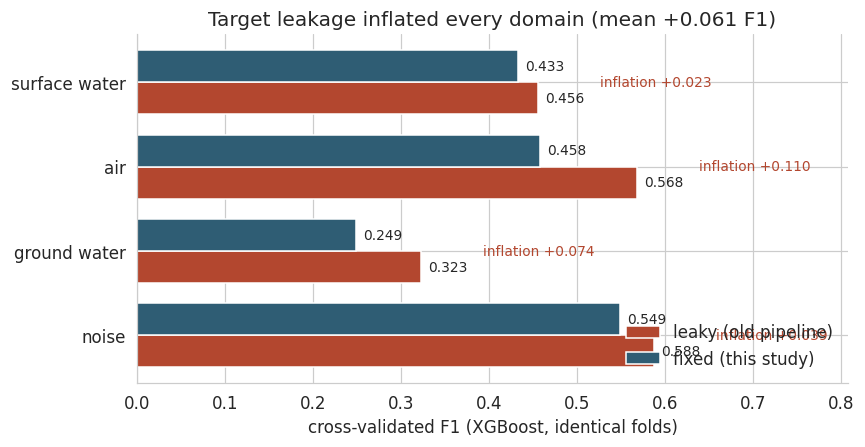

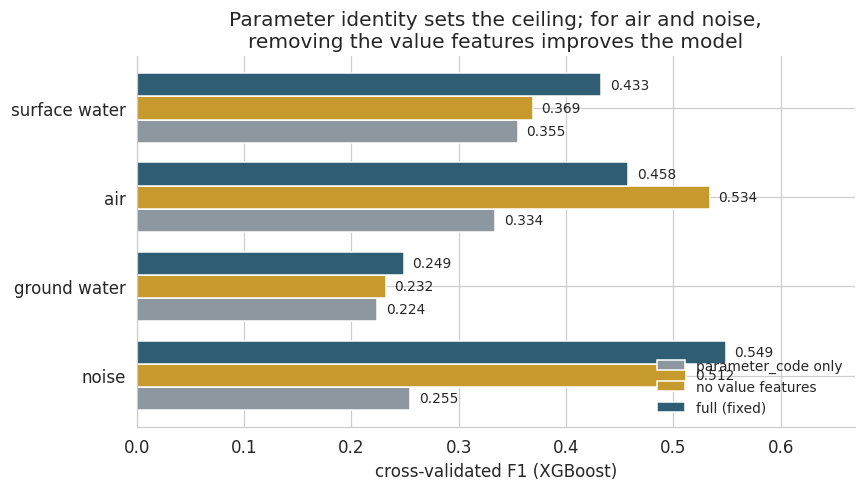

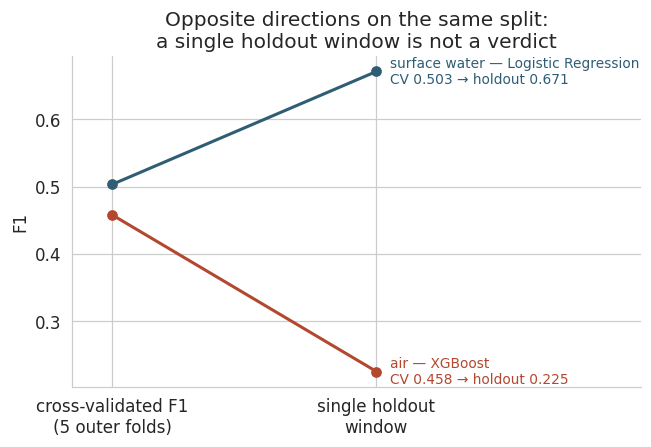

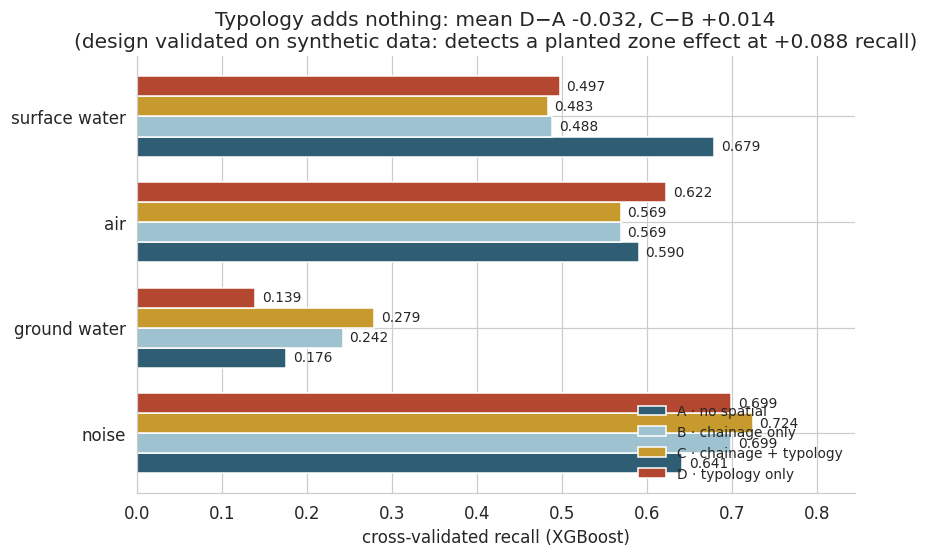

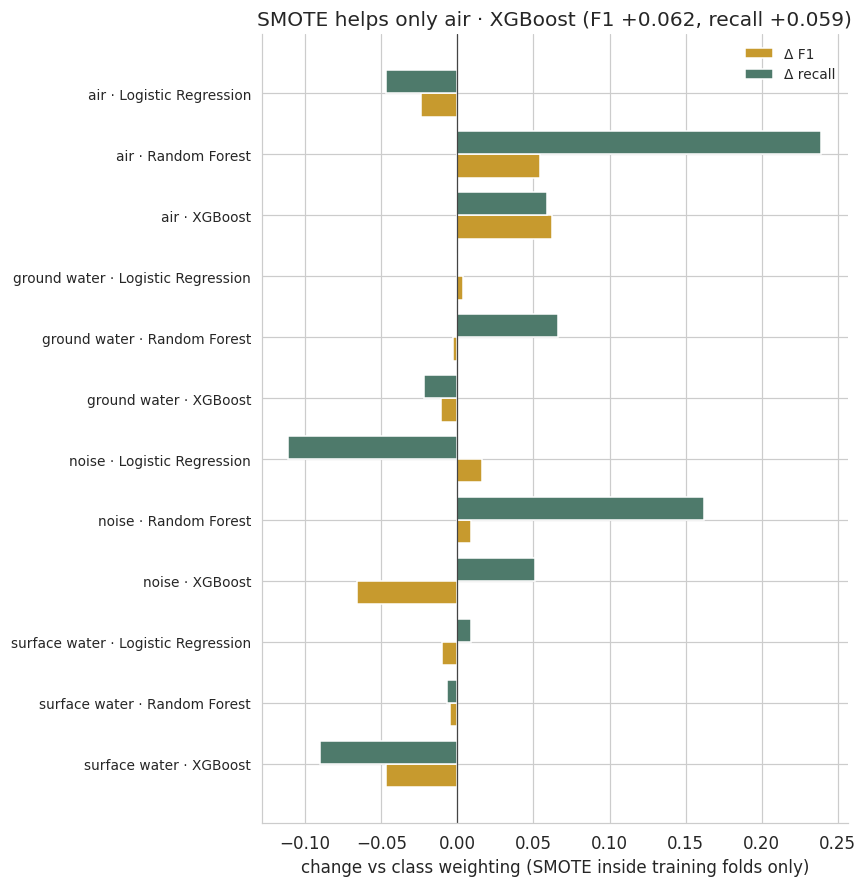

report figures saved to /content/drive/MyDrive/corridor_project/analysis :
   fig_leakage_audit.png
   fig_baselines.png
   fig_cv_vs_holdout.png
   fig_ablation_rq3.png
   fig_smote_sensitivity.png


In [16]:
# === CELL §9b: Report figures — validation comparisons =======================
# Static, publication-ready PNGs for §5 of the report, saved to OUT_DIR.
# Every figure is drawn from the audited frames already in memory
# (audit_df, baselines, results_df, smote_df, ablation) — no numbers are
# re-computed here, so the figures cannot drift from the tables.
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
C_LEAKY, C_FIXED = '#B3472F', '#2F5D74'
C_PARAM, C_NOVAL, C_FULL = '#8C97A0', '#C79A2E', '#2F5D74'
C_ABCD = ['#2F5D74', '#9FC2D1', '#C79A2E', '#B3472F']
DOM_ORDER = [d for d in ['surface_water', 'air', 'ground_water', 'noise']]
nice = lambda s: s.replace('_', ' ')

def _bar_labels(ax, bars, fmt='{:.3f}'):
    for b in bars:
        w = b.get_width()
        ax.text(w + 0.008, b.get_y() + b.get_height()/2, fmt.format(w),
                va='center', fontsize=9)

# --- 1. Leakage audit: leaky vs fixed CV F1 ---------------------------------
a = audit_df.copy()
a['tag'] = np.where(a.features.str.contains('leak'), 'leaky', 'fixed')
piv = a.pivot(index='domain', columns='tag', values='cv_f1').reindex(DOM_ORDER).dropna()
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(piv))
b1 = ax.barh(y + 0.19, piv['leaky'], 0.38, color=C_LEAKY, label='leaky (old pipeline)')
b2 = ax.barh(y - 0.19, piv['fixed'], 0.38, color=C_FIXED, label='fixed (this study)')
_bar_labels(ax, b1); _bar_labels(ax, b2)
for i, d in enumerate(piv.index):
    ax.text(max(piv.loc[d]) + 0.07, i, f"inflation +{piv.loc[d,'leaky']-piv.loc[d,'fixed']:.3f}",
            va='center', fontsize=9, color=C_LEAKY)
ax.set_yticks(y, [nice(d) for d in piv.index]); ax.invert_yaxis()
ax.set_xlabel('cross-validated F1 (XGBoost, identical folds)')
ax.set_xlim(0, min(1.0, piv.values.max() + 0.22))
ax.set_title('Target leakage inflated every domain '
             f'(mean +{(piv["leaky"]-piv["fixed"]).mean():.3f} F1)')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/fig_leakage_audit.png'); plt.show()

# --- 2. Baselines: the honest ceiling ---------------------------------------
ORDER_B = ['parameter_code only', 'no value features', 'full (fixed)']
piv = (baselines.pivot(index='domain', columns='baseline', values='cv_f1')
       .reindex(DOM_ORDER).dropna()[ORDER_B])
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(piv))
for k, (col, c) in enumerate(zip(ORDER_B, [C_PARAM, C_NOVAL, C_FULL])):
    bars = ax.barh(y + (1 - k) * 0.26, piv[col], 0.26, color=c, label=col)
    _bar_labels(ax, bars)
ax.set_yticks(y, [nice(d) for d in piv.index]); ax.invert_yaxis()
ax.set_xlabel('cross-validated F1 (XGBoost)')
ax.set_xlim(0, piv.values.max() + 0.12)
ax.set_title('Parameter identity sets the ceiling; for air and noise,\n'
             'removing the value features improves the model')
ax.legend(frameon=False, loc='lower right', fontsize=9)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/fig_baselines.png'); plt.show()

# --- 3. CV vs single holdout window -----------------------------------------
h = results_df.dropna(subset=['holdout_f1'])
if len(h):
    fig, ax = plt.subplots(figsize=(6.2, 4.2))
    for _, r in h.iterrows():
        col = C_FIXED if r.holdout_f1 >= r.cv_f1 else C_LEAKY
        ax.plot([0, 1], [r.cv_f1, r.holdout_f1], marker='o', color=col, lw=2)
        ax.annotate(f"{nice(r.domain)} — {r.model}\nCV {r.cv_f1:.3f} → holdout {r.holdout_f1:.3f}",
                    xy=(1, r.holdout_f1), xytext=(1.05, r.holdout_f1),
                    fontsize=9, va='center', color=col)
    ax.set_xticks([0, 1], ['cross-validated F1\n(5 outer folds)', 'single holdout\nwindow'])
    ax.set_xlim(-0.15, 2.0); ax.set_ylabel('F1')
    ax.set_title('Opposite directions on the same split:\na single holdout window is not a verdict')
    fig.tight_layout(); fig.savefig(f'{OUT_DIR}/fig_cv_vs_holdout.png'); plt.show()

# --- 4. Ablation (RQ3): four spatial configs --------------------------------
REC = {'recall_A_no_spatial': 'A · no spatial', 'recall_B_chainage_only': 'B · chainage only',
       'recall_C_chainage_typo': 'C · chainage + typology', 'recall_D_typology_only': 'D · typology only'}
ab = ablation.set_index('domain').reindex(DOM_ORDER).dropna(subset=list(REC))
fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(ab))
for k, (col, lab) in enumerate(REC.items()):
    bars = ax.barh(y + (1.5 - k) * 0.19, ab[col], 0.19, color=C_ABCD[k], label=lab)
    _bar_labels(ax, bars)
ax.set_yticks(y, [nice(d) for d in ab.index]); ax.invert_yaxis()
ax.set_xlabel('cross-validated recall (XGBoost)')
ax.set_xlim(0, ab[list(REC)].values.max() + 0.12)
ax.set_title(f'Typology adds nothing: mean D−A {ab.D_minus_A.mean():+.3f}, '
             f'C−B {ab.C_minus_B.mean():+.3f}\n'
             '(design validated on synthetic data: detects a planted zone effect at +0.088 recall)')
ax.legend(frameon=False, loc='lower right', fontsize=9)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/fig_ablation_rq3.png'); plt.show()

# --- 5. SMOTE sensitivity ----------------------------------------------------
if 'smote_df' in dir() and len(smote_df):
    s = smote_df.copy()
    s['label'] = s.domain.str.replace('_', ' ') + ' · ' + s.model
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(s) + 1.6))
    y = np.arange(len(s))
    ax.barh(y + 0.19, s.d_f1, 0.38, color=C_NOVAL, label='Δ F1')
    ax.barh(y - 0.19, s.d_recall, 0.38, color='#4E7A6B', label='Δ recall')
    ax.axvline(0, color='#444', lw=0.8)
    ax.set_yticks(y, s.label, fontsize=9); ax.invert_yaxis()
    ax.set_xlabel('change vs class weighting (SMOTE inside training folds only)')
    best = s.loc[s.d_f1.idxmax()]
    ax.set_title(f'SMOTE helps only {nice(best.domain)} · {best.model} '
                 f'(F1 {best.d_f1:+.3f}, recall {best.d_recall:+.3f})')
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout(); fig.savefig(f'{OUT_DIR}/fig_smote_sensitivity.png'); plt.show()

print("report figures saved to", OUT_DIR, ":")
for f in ['fig_leakage_audit', 'fig_baselines', 'fig_cv_vs_holdout',
          'fig_ablation_rq3', 'fig_smote_sensitivity']:
    print("  ", f + ".png")


## §10 Clustering (RQ2) — do behaviour-driven clusters recover geography?
Sites are clustered on **behaviour only** (per-domain exceedance rate). Geography is withheld from the
clustering and used solely to test correspondence, so the test is not circular.

`d` is re-created from the cleaned data here, because the figure loop in §9b reused the name as a loop variable.


In [17]:
d = df.copy()

sites clustered: 38 | features: ['exc_air', 'exc_ground_water', 'exc_noise', 'exc_surface_water']

k : silhouette
2 : 0.482
3 : 0.449
4 : 0.544
5 : 0.301
6 : 0.291
7 : 0.318

k : ARI   NMI   CramersV  (sensitivity)
3 : 0.065 0.295 0.613
4 : 0.026 0.145 0.312

chosen k=4 | KMeans-vs-Ward ARI 1.000

cluster x zone:
 zone_type  peri_urban  riverine  rural_agricultural  urban
cluster                                                   
0                  11         3                  19      1
1                   0         0                   1      0
2                   1         0                   0      1
3                   0         0                   1      0

correspondence: ARI=0.026 NMI=0.145 Cramer's V=0.312

cluster signatures:
          exc_air  exc_ground_water  exc_noise  exc_surface_water
cluster                                                         
0          0.080             0.064      0.148              0.337
1          0.000             0.262      0.173              

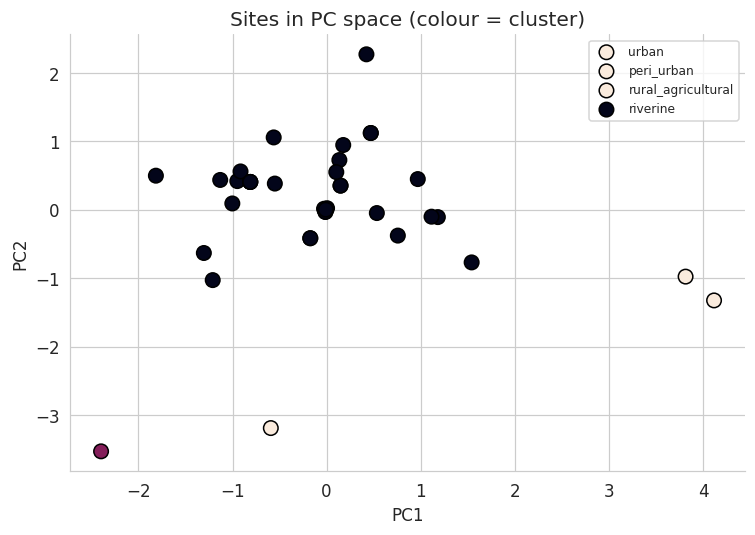

In [18]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.stats import chi2_contingency

piv = (d[(d.has_standard==1) & d.site_id.notna()]
         .groupby(['site_id','domain'])['exceedance'].mean().unstack())
piv.columns = ['exc_'+c for c in piv.columns]; piv = piv.dropna(axis=1, how='all')
feat = piv.reset_index().merge(typ[['site_id','zone_type']].drop_duplicates('site_id'), on='site_id', how='inner')
exc_cols = [c for c in feat.columns if c.startswith('exc_')]
feat[exc_cols] = feat[exc_cols].apply(lambda s: s.fillna(s.mean()))
X = StandardScaler().fit_transform(feat[exc_cols])
print(f"sites clustered: {len(feat)} | features: {exc_cols}")

sil = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=42).fit_predict(X))
       for k in range(2, min(8, len(feat)))}
print("\nk : silhouette"); [print(f"{k} : {v:.3f}") for k,v in sil.items()]

def corr(lab):
    ct = pd.crosstab(lab, feat['zone_type']); chi2 = chi2_contingency(ct)[0]
    n, (r, c) = ct.values.sum(), ct.shape
    return (adjusted_rand_score(feat['zone_type'], lab),
            normalized_mutual_info_score(feat['zone_type'], lab),
            np.sqrt(chi2/(n*(min(r,c)-1))))
n_zones = feat['zone_type'].nunique()
print("\nk : ARI   NMI   CramersV  (sensitivity)")
for k in sorted({3, n_zones, max(sil, key=sil.get)}):
    a,m,v = corr(KMeans(k, n_init=10, random_state=42).fit_predict(X)); print(f"{k} : {a:.3f} {m:.3f} {v:.3f}")

k = n_zones                       # align with #zones; silhouette is flat here
km = KMeans(k, n_init=10, random_state=42).fit_predict(X)
ward = fcluster(linkage(X,'ward'), t=k, criterion='maxclust')
feat['cluster'] = km
print(f"\nchosen k={k} | KMeans-vs-Ward ARI {adjusted_rand_score(km, ward):.3f}")
print("\ncluster x zone:\n", pd.crosstab(feat.cluster, feat.zone_type).to_string())
a,m,v = corr(km); print(f"\ncorrespondence: ARI={a:.3f} NMI={m:.3f} Cramer's V={v:.3f}")
print("\ncluster signatures:\n", feat.groupby('cluster')[exc_cols].mean().round(3).to_string())

pcs = PCA(2, random_state=42).fit_transform(X); feat['pc1'], feat['pc2'] = pcs[:,0], pcs[:,1]
plt.figure(figsize=(7,5))
for z in feat.zone_type.unique():
    g = feat[feat.zone_type==z]; plt.scatter(g.pc1, g.pc2, c=g.cluster, s=90, edgecolor='k', label=z)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Sites in PC space (colour = cluster)')
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_clustering_rq2.png', dpi=150); plt.show()
feat.to_csv(f'{OUT_DIR}/site_clusters.csv', index=False)

## §11 Interpretability — TreeSHAP, or coefficients where a linear model wins


surface_water: Logistic Regression — standardised coefficients


,feature,coefficient
7,value_lag1,2.872179
5,rule_limit_num,-2.124982
0,parameter_code,-1.586912
8,value_roll3,1.074495
6,chainage_km,-0.278926
2,year,-0.261783
1,month_num,0.063693
4,is_dry,-0.044795
3,is_monsoon,0.044795


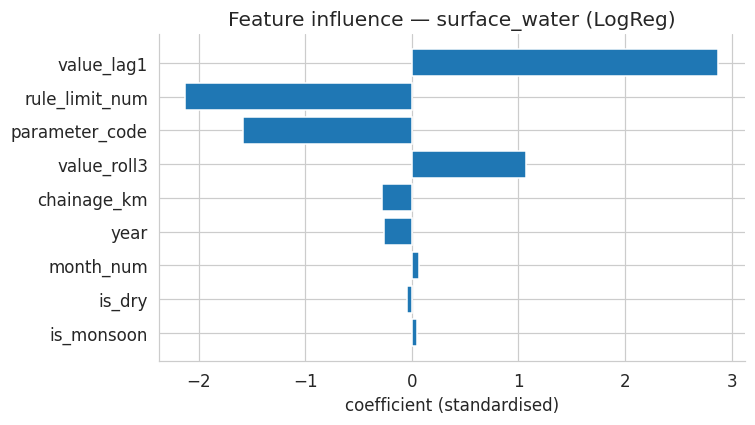

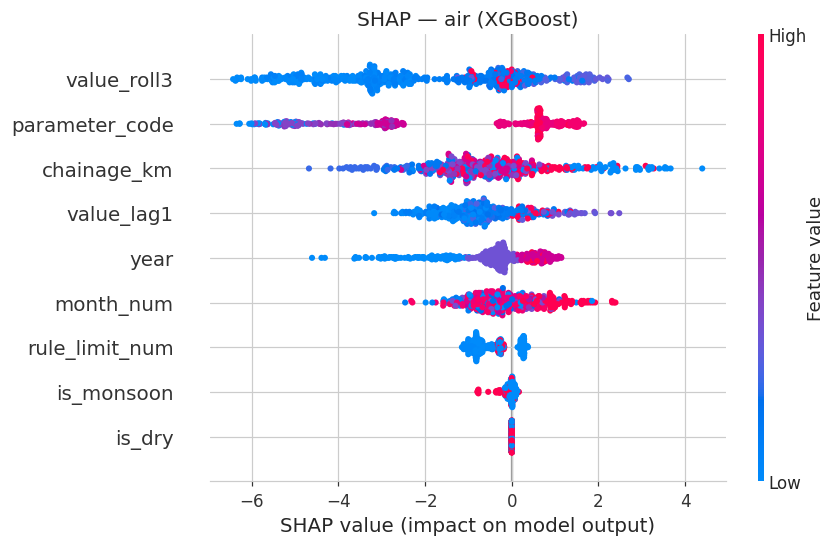

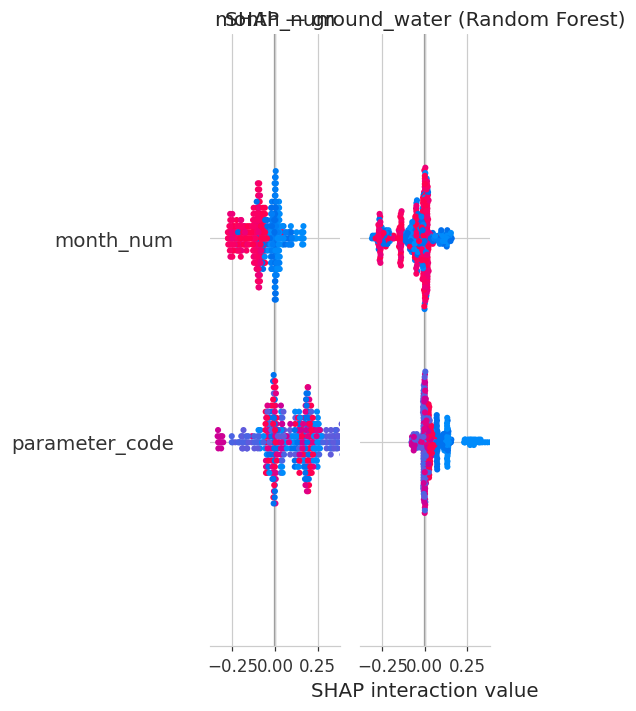

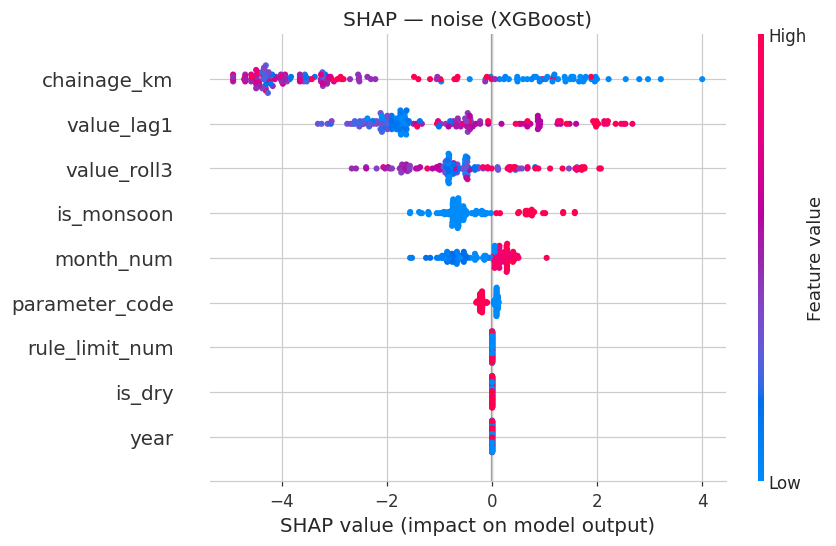


interpretability artefacts saved to /content/drive/MyDrive/corridor_project/analysis/shap


In [19]:
import shap
for dom, w in winners.items():
    if w['name']=='Logistic Regression':
        coef = pd.DataFrame({'feature': w['features'], 'coefficient': w['model'].coef_[0]})
        coef['abs'] = coef.coefficient.abs(); coef = coef.sort_values('abs', ascending=False)
        coef.to_csv(f'{OUT_DIR}/shap/coefficients_{dom}.csv', index=False)
        print(f"\n{dom}: Logistic Regression — standardised coefficients"); display(coef[['feature','coefficient']])
        plt.figure(figsize=(7,4)); plt.barh(coef.feature, coef.coefficient); plt.gca().invert_yaxis()
        plt.xlabel('coefficient (standardised)'); plt.title(f'Feature influence — {dom} (LogReg)')
        plt.tight_layout(); plt.savefig(f'{OUT_DIR}/shap/coefficients_{dom}.png', dpi=130); plt.show()
        continue
    sub = w['sub'].copy()
    for col in ['value_lag1','value_roll3']:
        sub[col] = sub[col].fillna(sub.groupby('parameter')[col].transform('median')).fillna(sub[col].median())
    sub = sub.dropna(subset=w['features'])
    Xs = sub[w['features']].sample(min(500, len(sub)), random_state=0)
    sv = shap.TreeExplainer(w['model']).shap_values(Xs)
    if isinstance(sv, list): sv = sv[1]
    plt.figure(); shap.summary_plot(sv, Xs, show=False)
    plt.title(f'SHAP — {dom} ({w["name"]})'); plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/shap/shap_{dom}.png', dpi=130, bbox_inches='tight'); plt.show()
print("\ninterpretability artefacts saved to", f'{OUT_DIR}/shap')

## §12 RQ1 — zone impact compared **within** each domain
Cross-domain averages are confounded: zones are monitored for different domains, so a zone measured only for
noise looks worse than one measured only for surface water. The coverage table below is itself a Pillar 2 finding.

In [20]:
zd = (d[(d.has_standard==1) & d.site_id.notna()]
        .groupby(['zone_type','domain'])
        .agg(exc_rate=('exceedance','mean'), n=('exceedance','size'), n_sites=('site_id','nunique'))
        .reset_index())
zd['exc_rate'] = zd.exc_rate.round(3)
print("exceedance rate by zone WITHIN domain (comparable):")
display(zd.pivot(index='zone_type', columns='domain', values='exc_rate'))
print("monitoring coverage — sites per zone x domain (the confound, and a Pillar 2 finding):")
display(zd.pivot(index='zone_type', columns='domain', values='n_sites').fillna(0).astype(int))
print("readings per zone x domain (small n = read descriptively):")
display(zd.pivot(index='zone_type', columns='domain', values='n').fillna(0).astype(int))
zd.to_csv(f'{OUT_DIR}/rq1_zone_within_domain.csv', index=False)

exceedance rate by zone WITHIN domain (comparable):


domain,air,ground_water,noise,surface_water
zone_type,,,,
peri_urban,0.138,0.075,0.236,0.435
riverine,0.000,0.000,0.000,0.325
rural_agricultural,0.092,0.103,0.000,0.313
urban,0.286,NaN,0.500,NaN


monitoring coverage — sites per zone x domain (the confound, and a Pillar 2 finding):


domain,air,ground_water,noise,surface_water
zone_type,,,,
peri_urban,6,4,6,1
riverine,2,2,1,1
rural_agricultural,8,6,5,8
urban,1,0,2,0


readings per zone x domain (small n = read descriptively):


domain,air,ground_water,noise,surface_water
zone_type,,,,
peri_urban,660,161,72,138
riverine,114,28,12,83
rural_agricultural,435,203,60,780
urban,7,0,24,0


## §13 Deployment — monitoring priority (risk-only until Pillars 2–3 land)

In [21]:
parts = []
for dom, w in winners.items():
    sub = w['sub'].copy()
    for col in ['value_lag1','value_roll3']:
        sub[col] = sub[col].fillna(sub.groupby('parameter')[col].transform('median')).fillna(sub[col].median())
    sub = sub.dropna(subset=w['features']); sub = sub[sub.site_id.notna()]
    Xp = sub[w['features']]
    if w['name']=='Logistic Regression': Xp = w['scaler'].transform(Xp)
    sub['p'] = w['model'].predict_proba(Xp)[:,1]
    parts.append(sub.groupby('site_id')['p'].mean().rename(f'risk_{dom}'))

risk = pd.concat(parts, axis=1)
risk['risk'] = risk.mean(axis=1)
risk = risk.reset_index().merge(typ[['site_id','zone_type']].drop_duplicates('site_id'), on='site_id', how='left')
risk['coverage_gap'] = np.nan     # Pillar 2 — EIA planned vs actual stations
risk['freq_gap']     = np.nan     # Pillar 3 — required vs actual cadence
risk['priority'] = risk['risk']   # composite once gaps exist: 0.5*risk + 0.25*cov + 0.25*freq
risk = risk.sort_values('priority', ascending=False)
risk.to_csv(f'{OUT_DIR}/site_priority.csv', index=False)
print(f"priority: {len(risk)} sites | zone_type missing: {risk.zone_type.isna().sum()}")
display(risk.head(10))
print("mean predicted risk by zone:"); display(risk.groupby('zone_type')['risk'].agg(['mean','count']).round(3))

priority: 38 sites | zone_type missing: 0


,site_id,risk_surface_water,risk_air,risk_ground_water,risk_noise,risk,zone_type,coverage_gap,freq_gap,priority
9,S35,0.373614,0.902565,NaN,NaN,0.638089,rural_agricultural,NaN,NaN,0.638089
31,S02,NaN,NaN,NaN,0.549186,0.549186,urban,NaN,NaN,0.549186
8,S34,0.389593,0.902565,0.236508,NaN,0.509555,rural_agricultural,NaN,NaN,0.509555
11,S03,NaN,0.319732,NaN,0.675000,0.497366,peri_urban,NaN,NaN,0.497366
6,S29,0.409402,0.571520,NaN,NaN,0.490461,rural_agricultural,NaN,NaN,0.490461
0,S06,0.472206,NaN,NaN,NaN,0.472206,peri_urban,NaN,NaN,0.472206
4,S22,0.470238,NaN,NaN,NaN,0.470238,rural_agricultural,NaN,NaN,0.470238
3,S18,0.450099,NaN,NaN,NaN,0.450099,rural_agricultural,NaN,NaN,0.450099
2,S15,0.432657,NaN,NaN,NaN,0.432657,rural_agricultural,NaN,NaN,0.432657
5,S26,0.419191,NaN,NaN,NaN,0.419191,rural_agricultural,NaN,NaN,0.419191


mean predicted risk by zone:


,mean,count
zone_type,,
peri_urban,0.213,12
riverine,0.139,3
rural_agricultural,0.215,21
urban,0.464,2


## §14 Time-series exports (pre-model vs post-model dashboard pages)

In [22]:
ts = d[(d.has_standard==1) & d.site_id.notna()].copy()
ts['month'] = ts.report_date.dt.strftime('%Y-%m')
act = (ts.groupby(['month','zone_type','domain'])
         .exceedance.agg(exc_rate='mean', n='size').reset_index())
act.to_csv(f'{DASH}/timeseries_actual.csv', index=False)

parts = []
for dom, w in winners.items():
    sub = w['sub'].copy()
    for col in ['value_lag1','value_roll3']:
        sub[col] = sub[col].fillna(sub.groupby('parameter')[col].transform('median')).fillna(sub[col].median())
    sub = sub.dropna(subset=w['features']); sub = sub[sub.site_id.notna()]
    Xp = sub[w['features']]
    if w['name']=='Logistic Regression': Xp = w['scaler'].transform(Xp)
    sub['p'] = w['model'].predict_proba(Xp)[:,1]
    sub['month'] = sub.report_date.dt.strftime('%Y-%m')
    parts.append(sub.groupby(['month','zone_type','domain']).p.agg(pred_risk='mean', n='size').reset_index())
pred = pd.concat(parts, ignore_index=True)
pred.to_csv(f'{DASH}/timeseries_predicted.csv', index=False)
print(f"timeseries_actual.csv {len(act)} rows | timeseries_predicted.csv {len(pred)} rows")

timeseries_actual.csv 136 rows | timeseries_predicted.csv 136 rows


## §15 Anonymised export + leak check — only this folder may be published

In [23]:
TRACEABLE = ['chainage','chainage_km','lat','lon','location','context_note','sample_id','_chkey','file','value']
def anon(x): return x.drop(columns=[c for c in TRACEABLE if c in x.columns], errors='ignore')

exc = (d[(d.has_standard==1) & d.site_id.notna()]
         .groupby(['site_id','domain']).exceedance.agg(exc_rate='mean', n='size').reset_index()
         .merge(typ[['site_id','zone_type']].drop_duplicates('site_id'), on='site_id', how='left'))
anon(exc).to_csv(f'{DASH}/exceedance_by_site_domain.csv', index=False)
anon(pd.read_csv(f'{OUT_DIR}/site_clusters.csv')).to_csv(f'{DASH}/site_clusters.csv', index=False)
results_df.to_csv(f'{DASH}/model_comparison.csv', index=False)
ablation.to_csv(f'{DASH}/ablation_rq3.csv', index=False)
anon(pd.read_csv(f'{OUT_DIR}/site_priority.csv')).to_csv(f'{DASH}/site_priority.csv', index=False)
audit_df.to_csv(f'{DASH}/leakage_audit.csv', index=False)
baselines.to_csv(f'{DASH}/baselines.csv', index=False)
if len(smote_df): smote_df.to_csv(f'{DASH}/smote_sensitivity.csv', index=False)

print("dashboard-ready (anonymised):")
for f in sorted(os.listdir(DASH)):
    chk = pd.read_csv(f'{DASH}/{f}'); leaks = [c for c in TRACEABLE if c in chk.columns]
    print(f"  {f:34s} rows={len(chk):5d}  {'LEAK: '+str(leaks) if leaks else 'clean'}")
print("\nSafe to publish: this folder only. Everything in", OUT_DIR, "still holds real chainage.")

dashboard-ready (anonymised):
  ablation_rq3.csv                   rows=    4  clean
  baselines.csv                      rows=   12  clean
  exceedance_by_site_domain.csv      rows=   53  clean
  leakage_audit.csv                  rows=    8  clean
  model_comparison.csv               rows=   12  clean
  parameter_regimes.csv              rows=   22  clean
  site_clusters.csv                  rows=   38  clean
  site_priority.csv                  rows=   38  clean
  smote_sensitivity.csv              rows=   12  clean
  timeseries_actual.csv              rows=  136  clean
  timeseries_predicted.csv           rows=  136  clean
  zone_regime_burden.csv             rows=    4  clean
  zone_regime_effort.csv             rows=    4  clean
  zone_regime_misalignment.csv       rows=    4  clean

Safe to publish: this folder only. Everything in /content/drive/MyDrive/corridor_project/analysis still holds real chainage.


## §16 Download everything for the dashboard

In [24]:
from google.colab import files
import shutil
shutil.make_archive('/content/dashboard_data', 'zip', DASH)
files.download('/content/dashboard_data.zip')

## §12b Parameter triage map — regimes, clustering, zone alignment
Groups parameters by behaviour (how often they exceed, and how persistent exceedances are), then compares the share of monitoring effort with the share of exceedances per regime in each zone. Outputs are also written to the dashboard folder.


silhouette (k=3): 0.715   (site clustering ARI was 0.026 — compare in the report)


,label,domain,n,exc_rate,persistence,regime
16,BOD5,surface_water,197,0.832,0.264,chronic
18,DO,surface_water,197,0.599,0.644,chronic
11,S,ground_water,56,0.161,-0.250,compliant
9,Fe,ground_water,56,0.125,0.000,compliant
15,Noise_Night,noise,84,0.083,0.302,compliant
7,As,ground_water,56,0.018,0.000,compliant
21,pH (SU),surface_water,110,0.009,0.000,compliant
0,CO,air,104,0.000,0.000,compliant
1,NO,air,146,0.000,0.000,compliant
2,NO2,air,146,0.000,0.000,compliant



monitoring EFFORT share per zone:


regime,chronic,compliant,episodic
zone_type,,,
peri_urban,0.045,0.560,0.396
riverine,0.170,0.391,0.438
rural_agricultural,0.209,0.404,0.387
urban,0.000,0.548,0.452


exceedance BURDEN share per zone:


regime,chronic,compliant,episodic
zone_type,,,
peri_urban,0.244,0.056,0.700
riverine,0.815,0.000,0.185
rural_agricultural,0.708,0.036,0.256
urban,0.000,0.286,0.714


misalignment (effort − burden; positive = effort spent where exceedance is absent or already certain):


regime,chronic,compliant,episodic
zone_type,,,
peri_urban,-0.199,0.504,-0.304
riverine,-0.645,0.391,0.253
rural_agricultural,-0.499,0.368,0.131
urban,0.000,0.262,-0.262


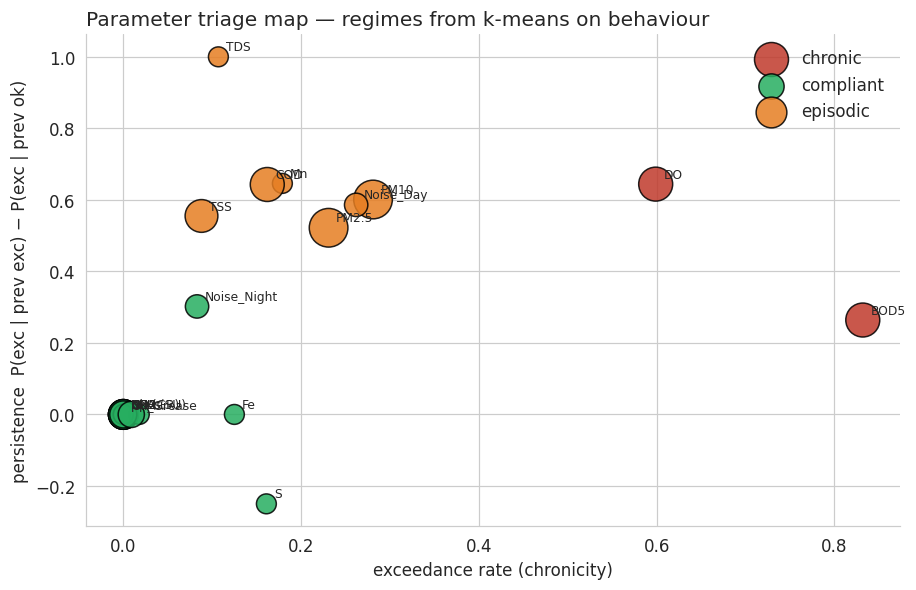

In [25]:
# === CELL §12b: Parameter triage map — regimes, clustering, zone alignment ===
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

MIN_N = 30
s = d[(d.has_standard==1) & d.site_id.notna()].sort_values(['domain','parameter','site_id','report_date'])

# --- per-parameter behaviour: chronicity (rate) + Markov persistence ---
recs=[]
for (dom,p), g in s.groupby(['domain','parameter']):
    n=len(g); rate=g.exceedance.mean()
    prev = g.groupby('site_id')['exceedance'].shift(1)
    pairs = g.assign(prev=prev).dropna(subset=['prev'])
    n1=(pairs.prev==1).sum(); n0=(pairs.prev==0).sum()
    p11=((pairs.prev==1)&(pairs.exceedance==1)).sum()/n1 if n1>=5 else np.nan
    p01=((pairs.prev==0)&(pairs.exceedance==1)).sum()/n0 if n0>=5 else np.nan
    persist=(p11-p01) if (pd.notna(p11) and pd.notna(p01)) else 0.0
    recs.append(dict(domain=dom, parameter=p, n=n, exc_rate=round(rate,3),
                     p11=round(p11,3) if pd.notna(p11) else np.nan,
                     p01=round(p01,3) if pd.notna(p01) else np.nan,
                     persistence=round(persist,3)))
reg=pd.DataFrame(recs); reg=reg[reg.n>=MIN_N].reset_index(drop=True)
dupes=reg.parameter.duplicated(keep=False)
reg['label']=np.where(dupes, reg.parameter+' ('+reg.domain.str[:2].str.upper()+')', reg.parameter)

# --- k-means on (rate, persistence); name clusters by centroid position ---
X=StandardScaler().fit_transform(reg[['exc_rate','persistence']])
km=KMeans(3, n_init=10, random_state=42).fit(X)
reg['cluster']=km.labels_
sil=silhouette_score(X, km.labels_)
cent=reg.groupby('cluster')[['exc_rate','persistence']].mean()
order=cent.exc_rate.sort_values().index.tolist()
NAME={order[0]:'compliant', order[-1]:'chronic'}
NAME[[c for c in cent.index if c not in NAME][0]]='episodic'
reg['regime']=reg.cluster.map(NAME)
print(f"silhouette (k=3): {sil:.3f}   (site clustering ARI was 0.026 — compare in the report)")
display(reg[['label','domain','n','exc_rate','persistence','regime']]
        .sort_values(['regime','exc_rate'], ascending=[True,False]))
reg.to_csv(f'{OUT_DIR}/parameter_regimes.csv', index=False)

# --- zone-wise monitoring alignment: effort share vs burden share per regime ---
z = s.merge(reg[['domain','parameter','regime']], on=['domain','parameter'], how='inner')
effort = z.pivot_table(index='zone_type', columns='regime', values='exceedance', aggfunc='size').fillna(0)
effort_share=(effort.T/effort.sum(axis=1)).T.round(3)
burden = z.pivot_table(index='zone_type', columns='regime', values='exceedance', aggfunc='sum').fillna(0)
burden_share=(burden.T/burden.sum(axis=1).replace(0,np.nan)).T.round(3)
mis=(effort_share-burden_share).round(3)
print("\nmonitoring EFFORT share per zone:"); display(effort_share)
print("exceedance BURDEN share per zone:"); display(burden_share)
print("misalignment (effort − burden; positive = effort spent where exceedance is absent or already certain):")
display(mis)
for name,frame in [('effort',effort_share),('burden',burden_share),('misalignment',mis)]:
    frame.to_csv(f'{OUT_DIR}/zone_regime_{name}.csv')
    frame.to_csv(f'{DASH}/zone_regime_{name}.csv')            # parameter/zone level — anonymisation-safe
reg.to_csv(f'{DASH}/parameter_regimes.csv', index=False)

# --- the triage figure ---
COL={'chronic':'#c0392b','episodic':'#e67e22','compliant':'#27ae60'}
fig,ax=plt.subplots(figsize=(8.5,5.5))
for rgm,g in reg.groupby('regime'):
    ax.scatter(g.exc_rate, g.persistence, s=g.n/max(1,reg.n.max())*600+40,
               c=COL[rgm], label=rgm, edgecolor='k', alpha=.85)
for _,r in reg.iterrows():
    ax.annotate(r.label, (r.exc_rate, r.persistence), xytext=(5,4), textcoords='offset points', fontsize=8)
ax.set_xlabel('exceedance rate (chronicity)')
ax.set_ylabel('persistence  P(exc | prev exc) − P(exc | prev ok)')
ax.set_title('Parameter triage map — regimes from k-means on behaviour', loc='left')
ax.legend(frameon=False); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_triage_map.png', dpi=150); plt.show()

## Appendix — diagnostics: report source and cadence
Checks how much of the analysis set comes from summary reports, the spacing between readings, and whether exceedance rates differ by report source for the same parameter and the same sites.


In [26]:
# === DIAGNOSTIC: how much quarterly (summary) data survives, and at what cadence? ===
print("A. Rows by source after cleaning & dedupe")
print(df.source.value_counts().to_string())
print(f"\nshare of analysis set that is quarterly/summary: {(df.source=='summary').mean()*100:.1f}%")

print("\nB. Source split per domain")
print(pd.crosstab(df.domain, df.source, margins=True).to_string())

print("\nC. Standardised rows only (what the models actually see)")
sd = df[df.has_standard==1]
print(pd.crosstab(sd.domain, sd.source).to_string())

print("\nD. Actual spacing between consecutive readings (same site+parameter)")
g = df.sort_values(['parameter','chainage','report_date'])
g['gap_days'] = g.groupby(['parameter','chainage'])['report_date'].diff().dt.days
print(g.groupby('source')['gap_days'].describe()[['count','25%','50%','75%']].round(0).to_string())
print("median ~30 = monthly cadence; ~90 = quarterly")

print("\nE. Monitoring window per domain per source")
print(df.groupby(['domain','source'])['report_month'].agg(['min','max','nunique']).to_string())

print("\nF. How many quarterly rows were discarded as duplicates of monthly?")
# reload the raw inputs: the names `a` and `b` were reused for other values above
original_a_data = pd.read_csv(f'{IN_DIR}/env_monitoring_long.csv')
original_b_data = pd.read_csv(f'{IN_DIR}/summary_extracted.csv')

raw = pd.concat([original_a_data.assign(source='monthly'), original_b_data.assign(source='summary')], ignore_index=True)
raw = raw.dropna(subset=['value','parameter','report_month'])
raw = raw[raw.report_month!='UNKNOWN']
kept = set(map(tuple, df[['report_month','domain','chainage','parameter']].values))
dropped = raw[~raw[['report_month','domain','chainage','parameter']].apply(tuple, axis=1).isin(kept)]
print(dropped.source.value_counts().to_string())

A. Rows by source after cleaning & dedupe
source
summary    2281
monthly    2125

share of analysis set that is quarterly/summary: 51.8%

B. Source split per domain
source         monthly  summary   All
domain                               
air                739      866  1605
ground_water       557        0   557
noise              172        0   172
surface_water      657     1415  2072
All               2125     2281  4406

C. Standardised rows only (what the models actually see)
source         monthly  summary
domain                         
air                581      812
ground_water       557        0
noise              172        0
surface_water      438      937

D. Actual spacing between consecutive readings (same site+parameter)
          count   25%   50%   75%
source                           
monthly  1679.0  30.0  31.0  31.0
summary  1655.0  30.0  31.0  61.0
median ~30 = monthly cadence; ~90 = quarterly

E. Monitoring window per domain per source
                       

In [27]:
# === DIAGNOSTIC 2: is exceedance rate confounded with report source? ===
s = df[df.has_standard==1]
print("exceedance rate by domain x source:")
print(s.pivot_table(index='domain', columns='source', values='exceedance',
                    aggfunc=['mean','size']).round(3).to_string())
print("\nsame parameter, both sources (the fair comparison):")
both = (s.groupby(['parameter','source']).exceedance.agg(['mean','size']).round(3)
          .unstack('source').dropna())
print(both.to_string())
print("\nIf summary rates are systematically lower for the SAME parameter,")
print("the apparent 2020-21 -> 2023 improvement is a source artefact, not a trend.")

exceedance rate by domain x source:
                 mean            size        
source        monthly summary monthly summary
domain                                       
air             0.033   0.149   581.0   812.0
ground_water    0.120     NaN   557.0     NaN
noise           0.169     NaN   172.0     NaN
surface_water   0.340   0.340   438.0   937.0

same parameter, both sources (the fair comparison):
              mean            size        
source     monthly summary monthly summary
parameter                                 
BOD5         0.849   0.827    73.0   202.0
CO           0.000   0.000    83.0    42.0
COD          0.411   0.040    73.0   202.0
DO           0.781   0.550    73.0   202.0
NO           0.000   0.000    83.0    84.0
NO2          0.000   0.000    83.0    84.0
O3           0.000   0.000    83.0    84.0
Oil_Grease   0.000   0.000    73.0    80.0
PM10         0.084   0.330    83.0   212.0
PM2.5        0.145   0.241    83.0   212.0
SO2          0.000   0.000    

In [28]:
for dom in ['air','surface_water']:
    g = df[df.domain==dom].groupby('source')['site_id'].apply(lambda s: set(s.dropna()))
    if len(g)==2:
        m, su = g.get('monthly',set()), g.get('summary',set())
        print(f"{dom}: monthly {len(m)} sites | summary {len(su)} | shared {len(m&su)}")

air: monthly 12 sites | summary 14 | shared 9
surface_water: monthly 10 sites | summary 16 | shared 8


In [29]:
# === FINAL CHECK: does the trend hold on SHARED sites only? ===
s = df[(df.has_standard==1) & df.site_id.notna()]
out = []
for dom in ['air','surface_water']:
    g = s[s.domain==dom]
    shared = set(g[g.source=='monthly'].site_id) & set(g[g.source=='summary'].site_id)
    sub = g[g.site_id.isin(shared)]
    t = (sub.groupby(['parameter','source']).exceedance.agg(['mean','size'])
           .round(3).unstack('source').dropna())
    print(f"\n--- {dom}: {len(shared)} shared sites ---")
    print(t.to_string())
print("\nIf PM10 still rises and COD still falls here, site coverage is not the explanation.")


--- air: 9 shared sites ---
             mean            size        
source    monthly summary monthly summary
parameter                                
CO          0.000   0.000      54      34
NO          0.000   0.000      54      76
NO2         0.000   0.000      54      76
O3          0.000   0.000      54      76
PM10        0.074   0.342      54     190
PM2.5       0.093   0.258      54     190
SO2         0.000   0.000      54      76

--- surface_water: 8 shared sites ---
              mean            size        
source     monthly summary monthly summary
parameter                                 
BOD5         0.863   0.809      51     136
COD          0.471   0.037      51     136
DO           0.765   0.522      51     136
Oil_Grease   0.000   0.000      51      57
TSS          0.000   0.132      51     121
pH           0.000   0.020      51      49

If PM10 still rises and COD still falls here, site coverage is not the explanation.
